# 04b - Statistical EDA of Stock Returns

## Objective

Notebooks 03 and 04 explored **price levels** (mainly Apple). This notebook goes one step deeper and studies the **daily returns** of all 8 stocks using descriptive statistics, distribution analysis, hypothesis tests and correlation analysis.

The analysis is deliberately kept simple: every section asks **one question**, answers it with **one plot or test**, and ends with a short **observation**.

### Sections

1. Data quality check (all 8 stocks)
2. Descriptive statistics of daily returns
3. Are returns normally distributed? (histogram, Q-Q plot, Jarque-Bera test)
4. Which stocks are riskier? (box plot, rolling volatility)
5. How are the stocks related? (correlation heatmap)
6. Hypothesis testing (t-test, Welch t-test, Levene test, Kruskal-Wallis test)
7. Time-series behaviour (stationarity test, autocorrelation)
8. What does this mean for the ML models? (class balance, feature correlation)

### Why returns instead of prices?

Prices trend upward and have different scales (USD vs INR, $20 vs $900), so they cannot be compared or tested directly.
**Daily return = (today's Adj Close / yesterday's Adj Close) - 1** is scale-free and comparable across stocks.
`Adj Close` is used because it accounts for stock splits and dividends.

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

plt.style.use("ggplot")

# all plots shown inside of the notebook
%matplotlib inline

sys.path.append("../src")
from config import STOCKS as stocks, FEATURES

US = stocks[:4]
INDIA = stocks[4:]

# one colour per market: blue = US, orange = India
COLORS = {s: ("#1f77b4" if s in US else "#ff7f0e") for s in stocks}

def save_fig(name):
    plt.savefig(f"../images/eda_{name}.png", dpi=130, bbox_inches="tight")

## 1. Data Quality Check

### Is the data complete and reliable for all 8 stocks?

In [2]:
data = {
    s: pd.read_csv(f"../data/cleaned/{s}.csv", parse_dates=["Date"]).set_index("Date")
    for s in stocks
}

overview = pd.DataFrame({
    s: {
        "Market": "US" if s in US else "India",
        "Rows": len(df),
        "Start": df.index.min().date(),
        "End": df.index.max().date(),
        "Missing values": int(df.isna().sum().sum()),
        "Duplicate dates": int(df.index.duplicated().sum()),
        "Zero-volume days": int((df["Volume"] == 0).sum()),
    }
    for s, df in data.items()
}).T

overview

,Market,Rows,Start,End,Missing values,Duplicate dates,Zero-volume days
AAPL,US,2945,2015-01-02,2026-09-18,0,0,0
MSFT,US,2945,2015-01-02,2026-09-18,0,0,0
NVDA,US,2945,2015-01-02,2026-09-18,0,0,0
AMZN,US,2945,2015-01-02,2026-09-18,0,0,0
RELIANCE.NS,India,2897,2015-01-01,2026-09-18,0,0,6
TCS.NS,India,2897,2015-01-01,2026-09-18,0,0,6
HDFCBANK.NS,India,2897,2015-01-01,2026-09-18,0,0,6
INFY.NS,India,2897,2015-01-01,2026-09-18,0,0,6


In [3]:
# Daily returns from Adjusted Close (first row has no previous day -> NaN)
returns = pd.DataFrame({s: data[s]["Adj Close"].pct_change() for s in stocks})

# the zero-volume days of an Indian stock
print("Zero-volume dates (RELIANCE.NS):")
print(data["RELIANCE.NS"][data["RELIANCE.NS"]["Volume"] == 0].index.strftime("%Y-%m-%d").tolist())

same_dates = all(
    data[s][data[s]["Volume"] == 0].index.equals(data["RELIANCE.NS"][data["RELIANCE.NS"]["Volume"] == 0].index)
    for s in INDIA
)
print("\nSame zero-volume dates in all 4 Indian stocks:", same_dates)

Zero-volume dates (RELIANCE.NS):
['2025-03-18', '2026-01-15', '2026-05-01', '2026-05-28', '2026-06-26', '2026-09-14']

Same zero-volume dates in all 4 Indian stocks: True


### Observation

- All 8 datasets have **no missing values and no duplicate dates**; each covers Jan 2015 to Sep 2026.
- US stocks have more rows than Indian stocks because the two markets have **different trading holidays**.
- The 4 Indian stocks have **6 zero-volume days on exactly the same dates**. A real stock does not trade zero shares on a normal day, so these look like **data-feed gaps** (only 0.2% of rows). They are not caught by `dropna()`, and they create infinite values in `Volume_Change` (a division by zero). No infinite values remain in the ML-ready files.

## 2. Descriptive Statistics of Daily Returns

### How large are the typical daily returns and how risky is each stock?

- **Annualised return** = mean daily return x 252 trading days
- **Annualised volatility** = daily standard deviation x √252
- **Return/Risk** = annualised return / annualised volatility (return earned per unit of risk)

In [4]:
summary = pd.DataFrame({
    "Mean (%)":            returns.mean() * 100,
    "Std Dev (%)":         returns.std() * 100,
    "Min (%)":             returns.min() * 100,
    "Max (%)":             returns.max() * 100,
    "Skewness":            returns.skew(),
    "Excess Kurtosis":     returns.kurt(),     # pandas kurt() = kurtosis - 3
    "Ann. Return (%)":     returns.mean() * 252 * 100,
    "Ann. Volatility (%)": returns.std() * np.sqrt(252) * 100,
})
summary["Return/Risk"] = summary["Ann. Return (%)"] / summary["Ann. Volatility (%)"]

summary.round(2)

,Mean (%),Std Dev (%),Min (%),Max (%),Skewness,Excess Kurtosis,Ann. Return (%),Ann. Volatility (%),Return/Risk
AAPL,0.11,1.81,-12.86,15.33,0.10,6.41,26.66,28.73,0.93
MSFT,0.10,1.74,-14.74,15.51,0.32,9.05,25.40,27.58,0.92
NVDA,0.25,3.03,-18.76,29.81,0.55,8.17,64.04,48.15,1.33
AMZN,0.12,2.08,-14.05,15.32,0.51,6.57,29.42,33.09,0.89
RELIANCE.NS,0.08,1.69,-13.15,14.72,0.34,8.39,19.87,26.86,0.74
TCS.NS,0.04,1.50,-9.41,9.85,0.01,3.74,9.58,23.84,0.40
HDFCBANK.NS,0.05,1.40,-12.61,11.60,-0.06,9.64,13.19,22.28,0.59
INFY.NS,0.05,1.69,-16.19,12.03,-0.26,8.03,12.94,26.83,0.48


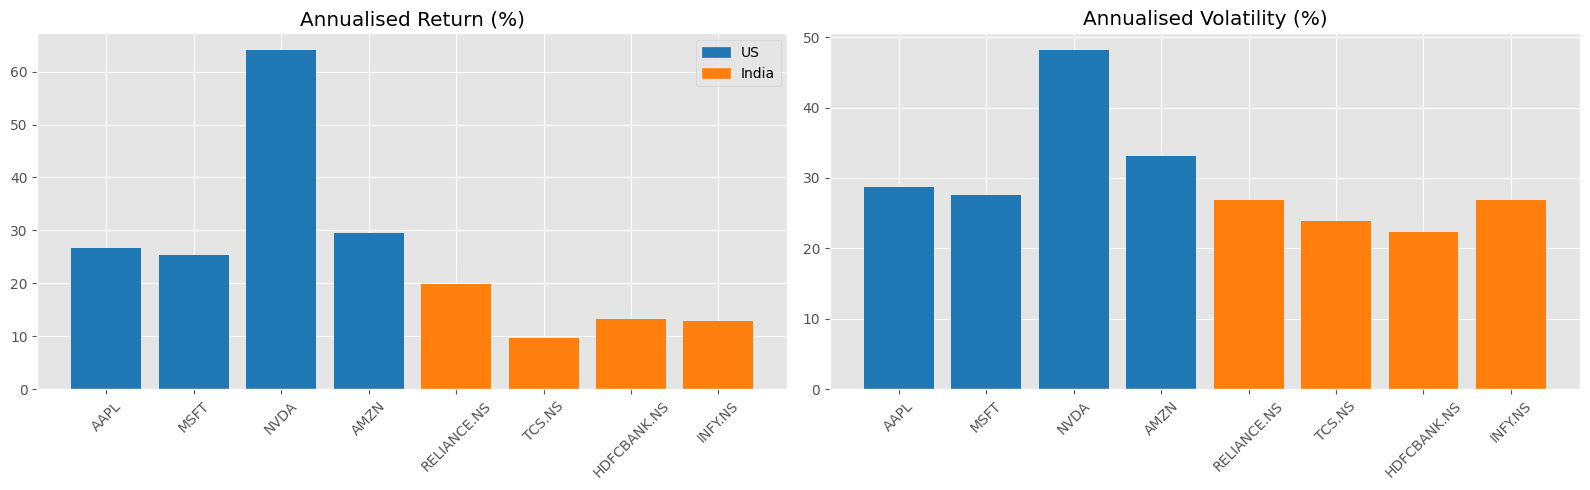

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, col, title in zip(
    axes,
    ["Ann. Return (%)", "Ann. Volatility (%)"],
    ["Annualised Return (%)", "Annualised Volatility (%)"],
):
    ax.bar(stocks, summary[col], color=[COLORS[s] for s in stocks])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)

# legend for the two markets
handles = [plt.Rectangle((0, 0), 1, 1, color="#1f77b4"), plt.Rectangle((0, 0), 1, 1, color="#ff7f0e")]
axes[0].legend(handles, ["US", "India"])

plt.tight_layout()
save_fig("return_vs_volatility")
plt.show()

### Observation

- Daily mean returns are tiny (0.04% to 0.25%) compared with daily standard deviations (1.4% to 3.0%). **Day-to-day noise is much larger than the average gain.**
- **NVIDIA** has the highest return (about 64% per year) and also the highest risk (about 48%).
- US stocks give higher returns **and** higher volatility than Indian stocks, and a better Return/Risk ratio (0.9 to 1.3 vs 0.4 to 0.7).
- Skewness is close to 0 for all stocks, but **excess kurtosis is positive (3.7 to 9.6)**, which means fat tails; this is tested formally in the next section.
- Caution: returns are in local currency (USD vs INR), and these are famous large companies that survived and grew (**survivorship bias**), so the results should not be generalised to all stocks.

## 3. Distribution of Returns

### Are daily returns normally distributed?

Many financial formulas assume returns follow a normal (bell-curve) distribution. We check this with three tools:

1. **Histogram** with a normal curve drawn on top
2. **Q-Q plot** - if data is normal, the points lie on the straight line
3. **Jarque-Bera test** - H0: returns are normal (based on skewness and kurtosis)

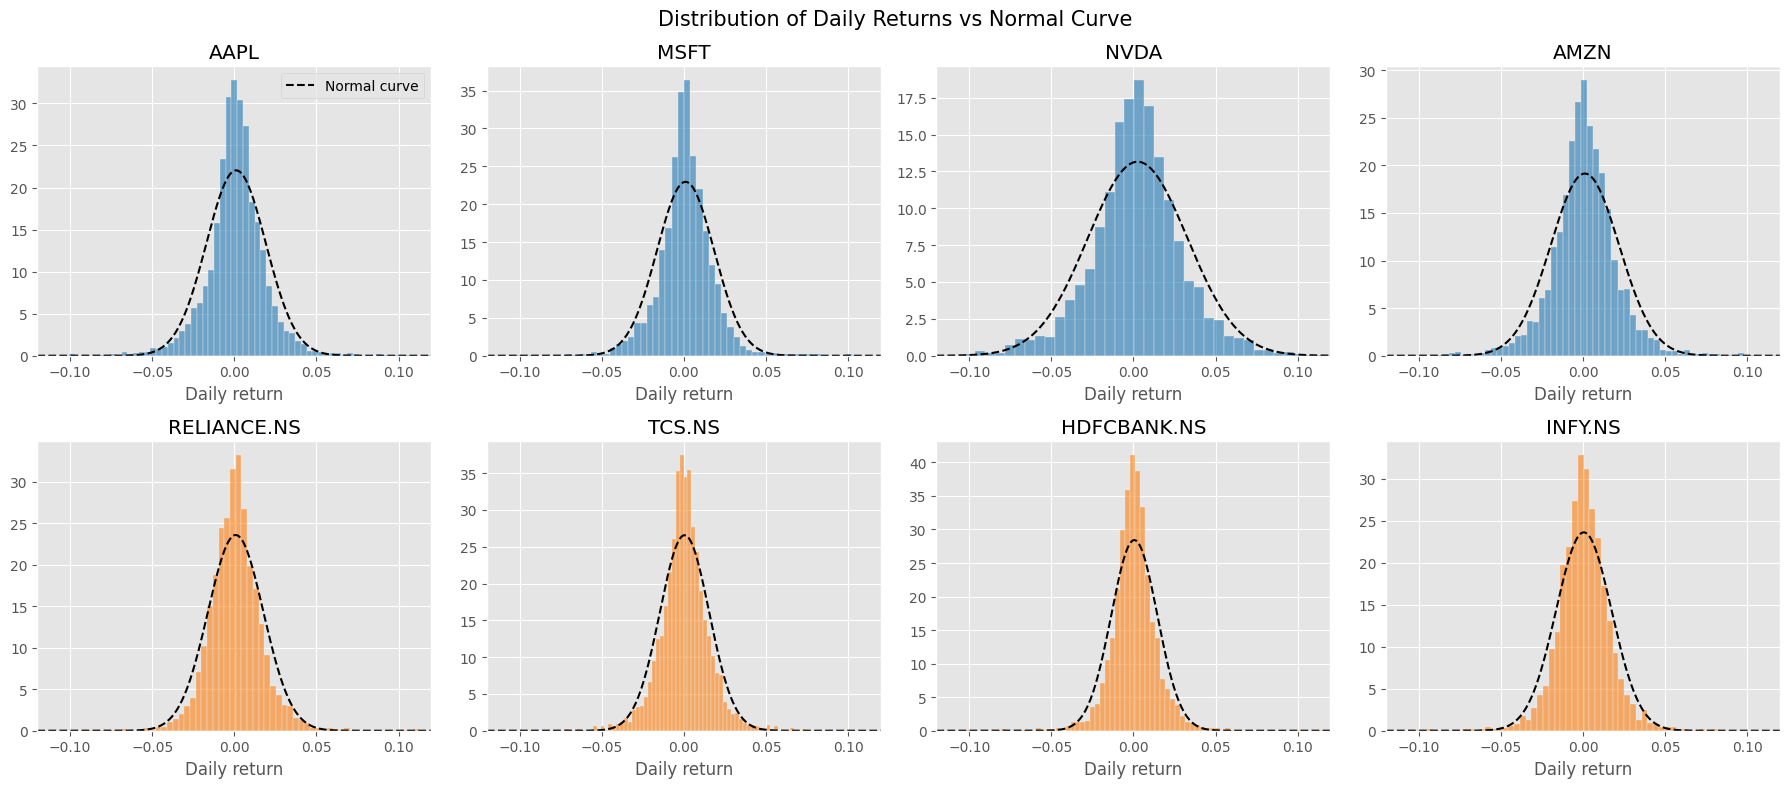

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, s in zip(axes.ravel(), stocks):
    r = returns[s].dropna()

    sns.histplot(r, bins=80, stat="density", color=COLORS[s], alpha=0.6, ax=ax)

    x = np.linspace(-0.12, 0.12, 300)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), "k--", lw=1.5, label="Normal curve")

    ax.set_xlim(-0.12, 0.12)
    ax.set_title(s)
    ax.set_xlabel("Daily return")
    ax.set_ylabel("")

axes[0, 0].legend()
fig.suptitle("Distribution of Daily Returns vs Normal Curve", fontsize=15)
plt.tight_layout()
save_fig("return_distributions")
plt.show()

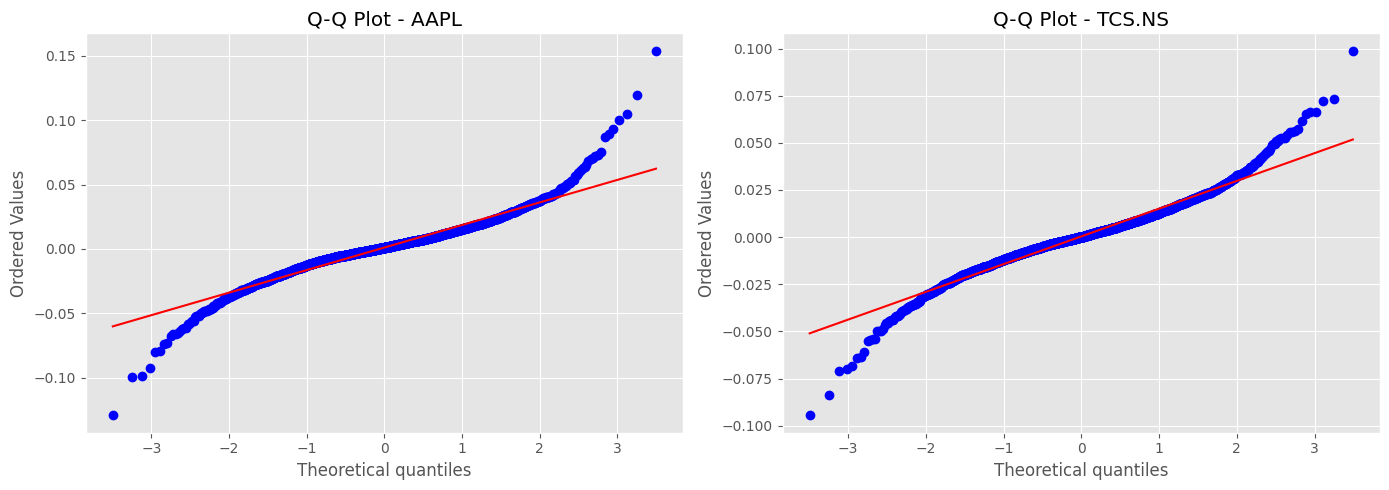

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, s in zip(axes, ["AAPL", "TCS.NS"]):
    stats.probplot(returns[s].dropna(), dist="norm", plot=ax)
    ax.set_title(f"Q-Q Plot - {s}")

plt.tight_layout()
save_fig("qq_plots")
plt.show()

In [8]:
rows = []

for s in stocks:
    r = returns[s].dropna()
    jb = stats.jarque_bera(r)
    z = (r - r.mean()) / r.std()          # z-score of every day

    rows.append({
        "Stock": s,
        "Skewness": r.skew(),
        "Excess Kurtosis": r.kurt(),
        "JB statistic": jb.statistic,
        "p-value": f"{jb.pvalue:.2e}",
        "Normal? (alpha=0.05)": "Yes" if jb.pvalue >= 0.05 else "No",
        "Days beyond +/-3 sigma (%)": (z.abs() > 3).mean() * 100,
    })

normality = pd.DataFrame(rows).set_index("Stock")
print("Expected % of days beyond +/-3 sigma if returns were normal: 0.27%\n")
normality.round(2)

Expected % of days beyond +/-3 sigma if returns were normal: 0.27%



,Skewness,Excess Kurtosis,JB statistic,p-value,Normal? (alpha=0.05),Days beyond +/-3 sigma (%)
Stock,,,,,,
AAPL,0.10,6.41,5020.73,0.00e+00,No,1.43
MSFT,0.32,9.05,10060.35,0.00e+00,No,1.49
NVDA,0.55,8.17,8316.17,0.00e+00,No,1.12
AMZN,0.51,6.57,5398.08,0.00e+00,No,1.53
RELIANCE.NS,0.34,8.39,8516.10,0.00e+00,No,1.21
TCS.NS,0.01,3.74,1677.62,0.00e+00,No,1.48
HDFCBANK.NS,-0.06,9.64,11175.57,0.00e+00,No,1.28
INFY.NS,-0.26,8.03,7772.90,0.00e+00,No,1.42


### Observation

- The histograms are **taller in the centre and have heavier tails** than the normal curve. The Q-Q plots bend away from the straight line at both ends.
- The Jarque-Bera p-value is practically 0 for **all 8 stocks**, so we **reject normality** for every stock.
- Days beyond +/-3 standard deviations occur about **1.1% to 1.5%** of the time, against 0.27% for a normal distribution. **Extreme days are roughly 4 to 6 times more common than a normal model predicts.**
- Implication: risk estimates that assume normality underestimate crashes and spikes. We therefore prefer **non-parametric** tests where it matters, and the tests with large samples (about 2,900 days) are still reliable through the Central Limit Theorem.

## 4. Risk and Volatility

### Which stocks are riskier, and is risk constant over time?

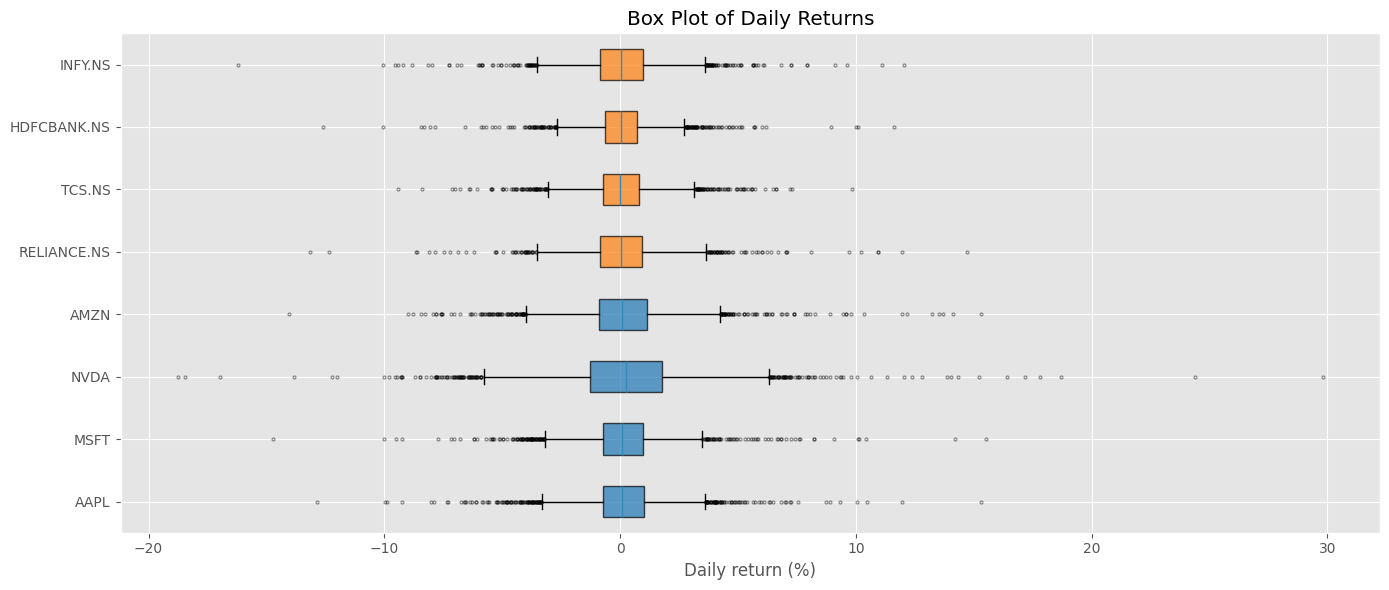

In [9]:
fig, ax = plt.subplots(figsize=(14, 6))

bp = ax.boxplot(
    [returns[s].dropna() * 100 for s in stocks],
    vert=False,
    patch_artist=True,
    flierprops=dict(marker="o", markersize=2, alpha=0.4),
)

for patch, s in zip(bp["boxes"], stocks):
    patch.set_facecolor(COLORS[s])
    patch.set_alpha(0.7)

ax.set_yticklabels(stocks)
ax.set_xlabel("Daily return (%)")
ax.set_title("Box Plot of Daily Returns")

plt.tight_layout()
save_fig("returns_boxplot")
plt.show()

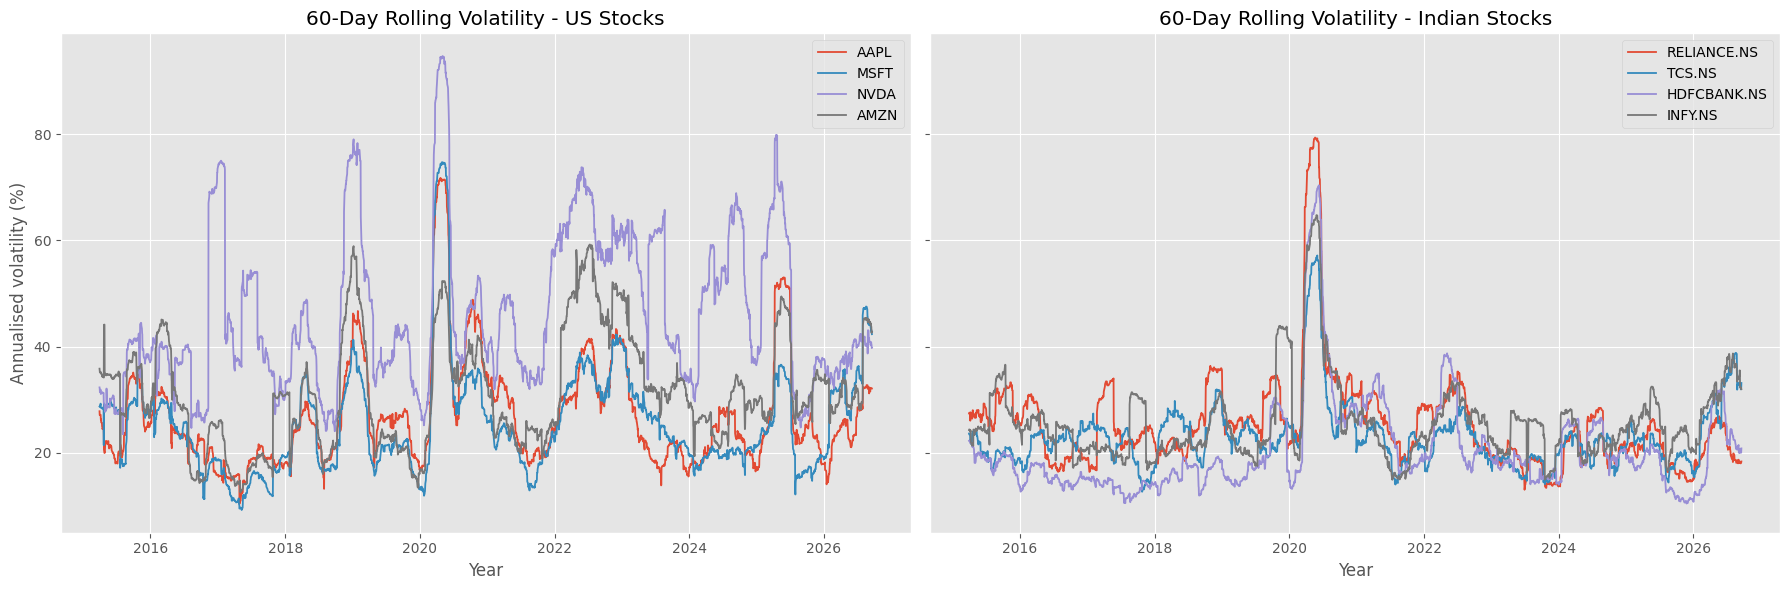

In [10]:
# 60-day rolling annualised volatility (calculated on each stock's own trading days)
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, group, title in zip(axes, [US, INDIA], ["US Stocks", "Indian Stocks"]):
    for s in group:
        r = returns[s].dropna()
        roll = r.rolling(60).std() * np.sqrt(252) * 100
        ax.plot(roll.index, roll.values, label=s, lw=1.3)
    ax.set_title(f"60-Day Rolling Volatility - {title}")
    ax.set_xlabel("Year")
    ax.legend()

axes[0].set_ylabel("Annualised volatility (%)")

plt.tight_layout()
save_fig("rolling_volatility")
plt.show()

In [11]:
# date of the highest 60-day volatility for every stock
peak = {}
for s in stocks:
    roll = returns[s].dropna().rolling(60).std() * np.sqrt(252) * 100
    peak[s] = {"Peak date": roll.idxmax().date(), "Peak volatility (%)": round(roll.max(), 1)}

pd.DataFrame(peak).T

,Peak date,Peak volatility (%)
AAPL,2020-04-22,71.7
MSFT,2020-05-05,74.7
NVDA,2020-05-04,94.7
AMZN,2022-07-11,59.2
RELIANCE.NS,2020-05-20,79.3
TCS.NS,2020-06-01,57.2
HDFCBANK.NS,2020-06-09,70.3
INFY.NS,2020-05-27,64.7


### Observation

- The box plot shows **NVIDIA has the widest spread** of daily returns, while **HDFC Bank and TCS are the most stable**.
- Every stock has many outlier days on both sides of the box, which matches the fat tails found earlier.
- Volatility is **not constant**. Seven of the eight stocks reach their highest 60-day volatility between **April and June 2020 (COVID-19 crash)**; Amazon peaks later, in mid-2022. For Indian stocks the 2020 spike is the single dominant event, while US stocks (especially NVIDIA) also show several other high-volatility periods (late 2018, 2022, 2025).
- Calm and turbulent periods come in groups (**volatility clustering**); this is confirmed statistically in Section 7.

## 5. Correlation Analysis

### How are the stocks related to each other?

Correlation is computed on **daily returns** (not prices, because two trending prices will always look correlated). Only dates on which **both** US and Indian markets were open are used.

Common trading days used: 2804


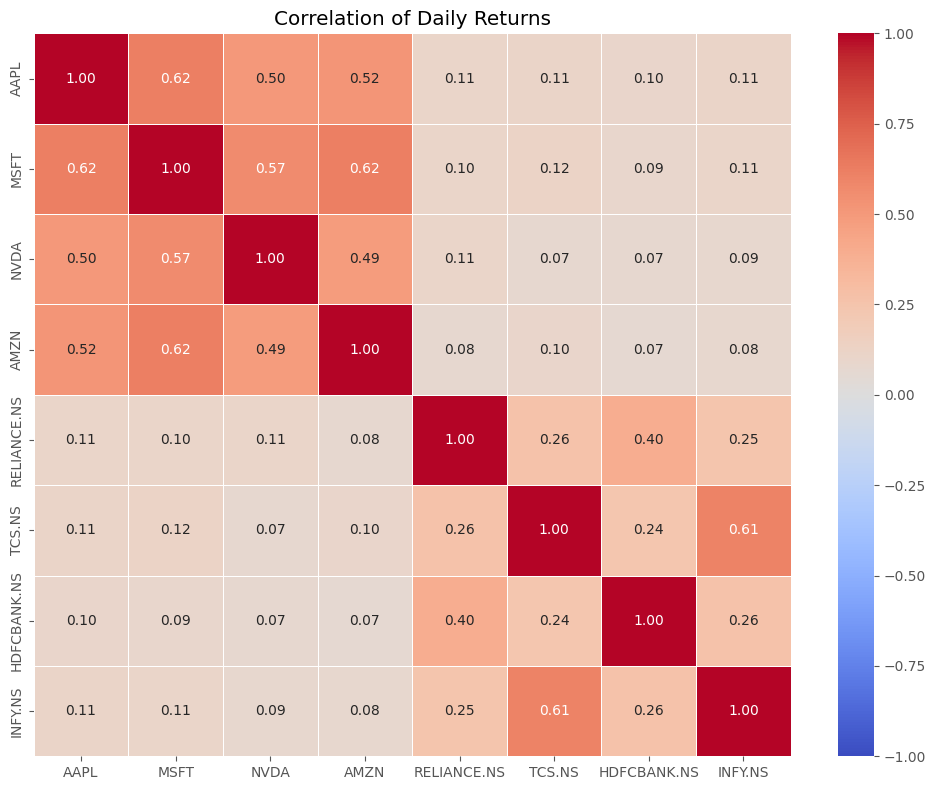

In [12]:
common = returns.dropna()                  # dates where all 8 stocks traded
print("Common trading days used:", len(common))

corr = common.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation of Daily Returns")
plt.tight_layout()
save_fig("returns_correlation")
plt.show()

In [13]:
def avg_corr(group_a, group_b):
    vals = [corr.loc[i, j] for i in group_a for j in group_b if i != j]
    return np.mean(vals)

print(f"Average correlation  US - US       : {avg_corr(US, US):.2f}")
print(f"Average correlation  India - India : {avg_corr(INDIA, INDIA):.2f}")
print(f"Average correlation  US - India    : {avg_corr(US, INDIA):.2f}")

Average correlation  US - US       : 0.55
Average correlation  India - India : 0.34
Average correlation  US - India    : 0.09


### Observation

- Stocks **within the same market move together**: US-US average correlation is about 0.55 and India-India about 0.34.
- **US and Indian stocks are almost unrelated** on the same day (about 0.09). Holding both markets would therefore give better **diversification**. Part of this low value is because the Indian market closes before the US market opens, so US news reaches Indian prices on the next day.
- Strong pairs share a business: **TCS and Infosys (0.61)** are both IT-services companies, and **Microsoft with Apple/Amazon (0.62)** are large US technology companies. This shows a **sector effect**.
- No pair has a negative correlation.

## 6. Hypothesis Testing

Significance level used in every test: **alpha = 0.05** (if p-value < 0.05 we reject H0).

### 6.1 Does each stock earn a positive average daily return?

One-sample t-test: **H0:** mean daily return = 0, **H1:** mean daily return != 0

In [14]:
rows = []

for s in stocks:
    r = returns[s].dropna()
    t = stats.ttest_1samp(r, 0)
    rows.append({
        "Stock": s,
        "Mean daily return (%)": r.mean() * 100,
        "t-statistic": t.statistic,
        "p-value": round(t.pvalue, 4),
        "Reject H0?": "Yes" if t.pvalue < 0.05 else "No",
    })

ttest_table = pd.DataFrame(rows).set_index("Stock")
ttest_table.round(3)

,Mean daily return (%),t-statistic,p-value,Reject H0?
Stock,,,,
AAPL,0.106,3.172,0.002,Yes
MSFT,0.101,3.147,0.002,Yes
NVDA,0.254,4.546,0.000,Yes
AMZN,0.117,3.039,0.002,Yes
RELIANCE.NS,0.079,2.508,0.012,Yes
TCS.NS,0.038,1.362,0.173,No
HDFCBANK.NS,0.052,2.006,0.045,Yes
INFY.NS,0.051,1.635,0.102,No


### Observation

- For **6 of 8 stocks** the average daily return is significantly different from 0 (and positive). TCS (p = 0.17) and Infosys (p = 0.10) are **not** significant: their small average gain cannot be separated from daily noise.
- HDFC Bank is only just significant (p = 0.045), so it is a weak result.

### 6.2 Do US and Indian markets differ in return and risk?

For each market, an **equal-weight portfolio** (average of its 4 stocks each day) is built. Then:

- **Welch t-test** - H0: both markets have the same mean daily return
- **Levene test** - H0: both markets have the same variance (risk)

,US portfolio,India portfolio
Days,2944.000,2896.000
Mean daily return (%),0.144,0.055
Std dev (%),1.770,1.114


Welch t-test : t = 2.31, p-value = 0.0210
Levene test  : W = 272.0, p-value = 9.32e-60


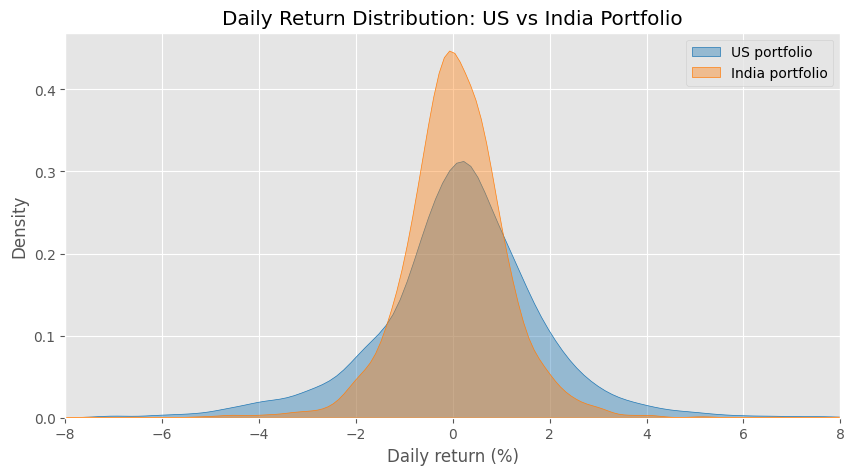

In [15]:
us_port = returns[US].dropna().mean(axis=1)
india_port = returns[INDIA].dropna().mean(axis=1)

compare = pd.DataFrame({
    "US portfolio":    [len(us_port), us_port.mean() * 100, us_port.std() * 100],
    "India portfolio": [len(india_port), india_port.mean() * 100, india_port.std() * 100],
}, index=["Days", "Mean daily return (%)", "Std dev (%)"])

display(compare.round(3))

welch = stats.ttest_ind(us_port, india_port, equal_var=False)
levene = stats.levene(us_port, india_port)

print(f"Welch t-test : t = {welch.statistic:.2f}, p-value = {welch.pvalue:.4f}")
print(f"Levene test  : W = {levene.statistic:.1f}, p-value = {levene.pvalue:.2e}")

plt.figure(figsize=(10, 5))
sns.kdeplot(us_port * 100, label="US portfolio", color="#1f77b4", fill=True, alpha=0.4)
sns.kdeplot(india_port * 100, label="India portfolio", color="#ff7f0e", fill=True, alpha=0.4)
plt.xlim(-8, 8)
plt.xlabel("Daily return (%)")
plt.title("Daily Return Distribution: US vs India Portfolio")
plt.legend()
save_fig("us_vs_india_distribution")
plt.show()

### Observation

- Mean daily return: US **0.144%** vs India **0.055%**. The Welch t-test gives p = 0.02, so the US market earned a **significantly higher** average return in this period.
- The Levene test gives a p-value of almost 0, so the **risk (variance) of the two markets is significantly different**: the US portfolio is more volatile (std 1.77% vs 1.11%). The density plot shows the same: the Indian curve is narrower.
- Limitation: the portfolios are built only from 4 famous stocks each, and the returns are in different currencies.

### 6.3 Is there a day-of-the-week effect?

Do some weekdays give better returns than others? We use the **Kruskal-Wallis test** (the non-parametric version of ANOVA, suitable because returns are not normal). **H0:** returns are the same on all 5 weekdays.

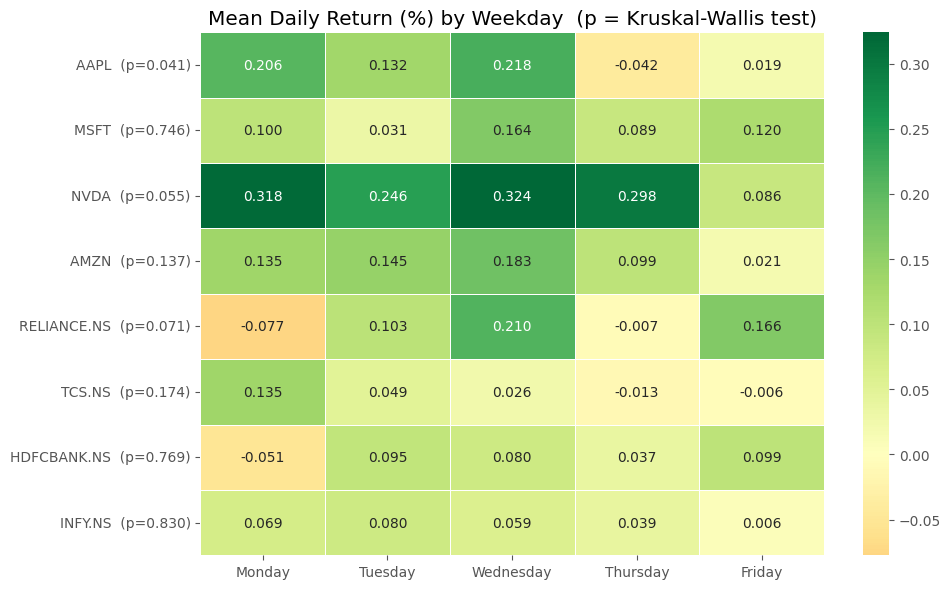

Significant at 0.05                      : ['AAPL']
Significant after Bonferroni (0.0063)     : []


In [16]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

mean_by_day = {}
p_values = {}

for s in stocks:
    r = returns[s].dropna()
    groups = [r[r.index.dayofweek == d] for d in range(5)]
    mean_by_day[s] = [g.mean() * 100 for g in groups]
    p_values[s] = stats.kruskal(*groups).pvalue

heat = pd.DataFrame(mean_by_day, index=order).T
heat.index = [f"{s}  (p={p_values[s]:.3f})" for s in stocks]

plt.figure(figsize=(10, 6))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="RdYlGn", center=0, linewidths=0.5)
plt.title("Mean Daily Return (%) by Weekday  (p = Kruskal-Wallis test)")
plt.tight_layout()
save_fig("weekday_effect")
plt.show()

bonferroni_alpha = 0.05 / len(stocks)
print(f"Significant at 0.05                      : {[s for s in stocks if p_values[s] < 0.05]}")
print(f"Significant after Bonferroni ({bonferroni_alpha:.4f})     : {[s for s in stocks if p_values[s] < bonferroni_alpha]}")

### Observation

- Only **AAPL (p = 0.041)** is significant at 5%. When 8 tests are run, about 0.4 "significant" results are expected **by pure chance**. With the stricter **Bonferroni correction** (alpha = 0.05 / 8 = 0.00625) **no stock is significant**.
- Conclusion: **no reliable day-of-week effect**, so the weekday is not a useful feature for the ML models.

## 7. Time-Series Behaviour

### 7.1 Are prices and returns stationary?

A series is **stationary** if its mean and variance do not drift over time. We use the **Augmented Dickey-Fuller (ADF) test**: **H0:** the series is non-stationary. (p < 0.05 means stationary.)

In [17]:
rows = []

for s in stocks:
    p_price = adfuller(data[s]["Adj Close"].dropna())[1]
    p_ret = adfuller(returns[s].dropna())[1]
    rows.append({
        "Stock": s,
        "Price p-value": round(p_price, 4),
        "Price stationary?": "Yes" if p_price < 0.05 else "No",
        "Return p-value": f"{p_ret:.1e}",
        "Return stationary?": "Yes" if p_ret < 0.05 else "No",
    })

pd.DataFrame(rows).set_index("Stock")

,Price p-value,Price stationary?,Return p-value,Return stationary?
Stock,,,,
AAPL,0.9950,No,3.9e-30,Yes
MSFT,0.9463,No,2.0e-30,Yes
NVDA,0.9985,No,0.0e+00,Yes
AMZN,0.8934,No,0.0e+00,Yes
RELIANCE.NS,0.6779,No,3.1e-29,Yes
TCS.NS,0.6049,No,5.3e-21,Yes
HDFCBANK.NS,0.4839,No,0.0e+00,Yes
INFY.NS,0.6161,No,0.0e+00,Yes


### 7.2 Can today's return predict tomorrow's return?

The **autocorrelation function (ACF)** shows the correlation of a series with its own past values. Bars outside the shaded band are statistically significant. We compare the returns with the **squared returns** (squared returns measure the size of the move, ignoring direction).

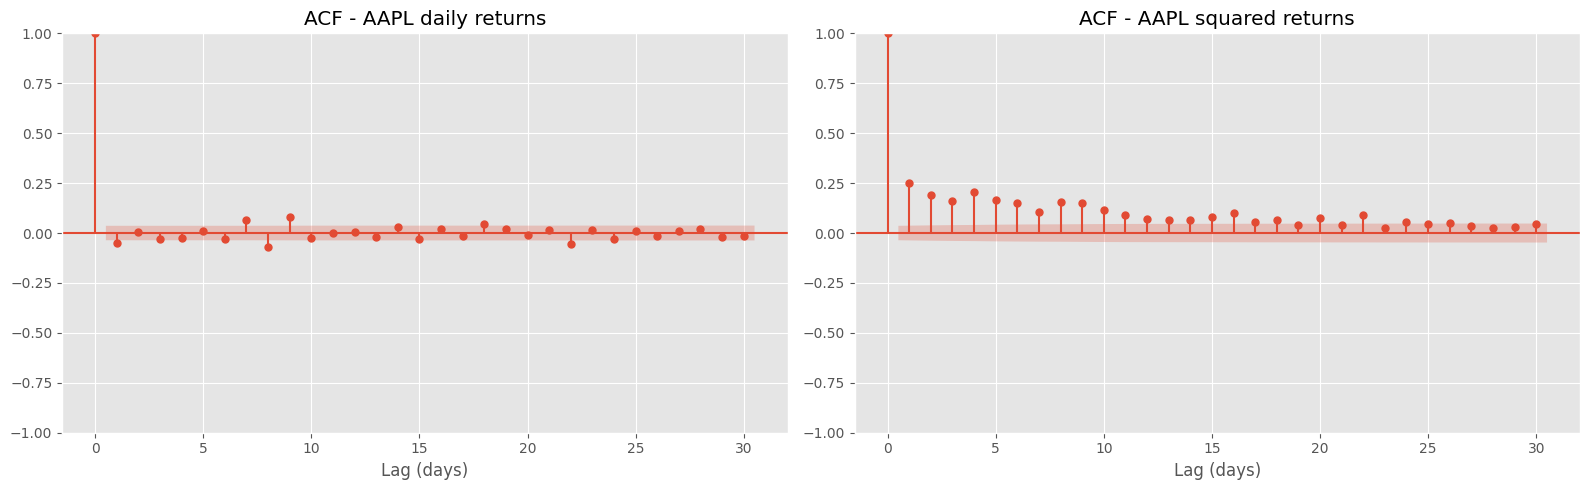

Lag-1 autocorrelation of returns         : -0.051
Lag-1 autocorrelation of squared returns : 0.253


In [18]:
r = returns["AAPL"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(r, lags=30, ax=axes[0], title="ACF - AAPL daily returns")
plot_acf(r ** 2, lags=30, ax=axes[1], title="ACF - AAPL squared returns")
for ax in axes:
    ax.set_xlabel("Lag (days)")

plt.tight_layout()
save_fig("acf_returns")
plt.show()

print(f"Lag-1 autocorrelation of returns         : {r.autocorr(1):.3f}")
print(f"Lag-1 autocorrelation of squared returns : {(r ** 2).autocorr(1):.3f}")

### Observation

- **Prices are non-stationary** for all 8 stocks (p-values far above 0.05): they wander and trend like a random walk. **Returns are stationary** (p ≈ 0). This is why analysis and modelling should be based on returns or ratios instead of raw prices.
- The ACF of returns is **very small**: lag-1 autocorrelation is only -0.05 and no bar exceeds about 0.1, so a stock's **direction is almost unpredictable from its own past returns**.
- The ACF of squared returns is **clearly positive and decays slowly** (lag-1 = 0.25, still significant after 30 days): large moves are followed by large moves, i.e. **volatility clustering**. The *size* of tomorrow's move is partly predictable, but the *direction* is not.

## 8. Link to the Machine Learning Models

The ML models predict whether the price will be **higher after 1, 5 or 20 trading days** (`Target_1D`, `Target_5D`, `Target_20D`).

### 8.1 Is the target balanced?

A model that always answers "Up" would be correct as often as the share of "Up" days. This is the **baseline** any model must beat.

In [19]:
horizons = ["1D", "5D", "20D"]

balance = pd.DataFrame({
    h: {
        s: pd.read_csv(f"../data/ml_ready/{s}_{h}_ml.csv")[f"Target_{h}"].mean() * 100
        for s in stocks
    }
    for h in horizons
})

balance.round(1)

,1D,5D,20D
AAPL,52.8,57.2,62.6
MSFT,53.1,58.3,63.4
NVDA,54.2,59.3,66.4
AMZN,53.2,56.7,64.6
RELIANCE.NS,51.7,54.7,55.3
TCS.NS,49.9,51.6,52.6
HDFCBANK.NS,51.0,54.0,58.4
INFY.NS,50.6,53.9,57.6


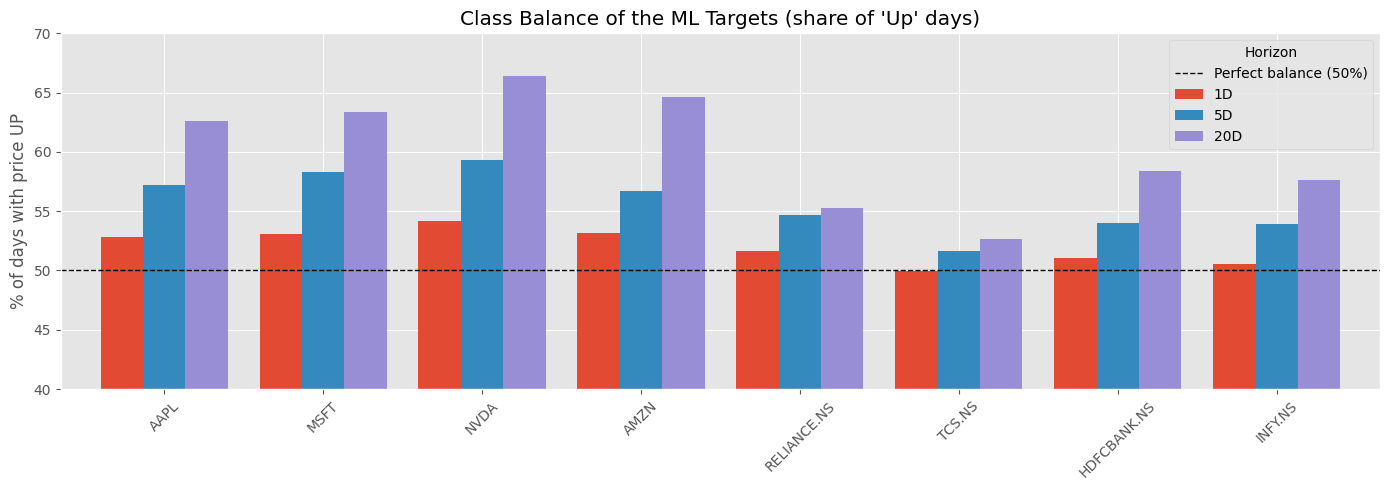

In [20]:
ax = balance.plot(kind="bar", figsize=(14, 5), width=0.8)
ax.axhline(50, color="black", linestyle="--", lw=1, label="Perfect balance (50%)")
ax.set_ylabel("% of days with price UP")
ax.set_ylim(40, 70)
ax.set_title("Class Balance of the ML Targets (share of 'Up' days)")
ax.legend(title="Horizon")
plt.xticks(rotation=45)

plt.tight_layout()
save_fig("target_balance")
plt.show()

### Observation

- At 1 day the classes are nearly balanced (50% to 54% up). The share of **"Up" grows with the horizon**: for 20 days it reaches **63% to 66% for the US tech stocks**, because of the long-term upward trend (positive drift).
- So an "always Up" model already scores about **66% accuracy on NVIDIA at 20D**. **Accuracy alone can be misleading**, which justifies the use of precision, recall and F1 in the project.

### 8.2 Do the engineered features relate to the target?

Apple (1-day horizon) is used as the example.

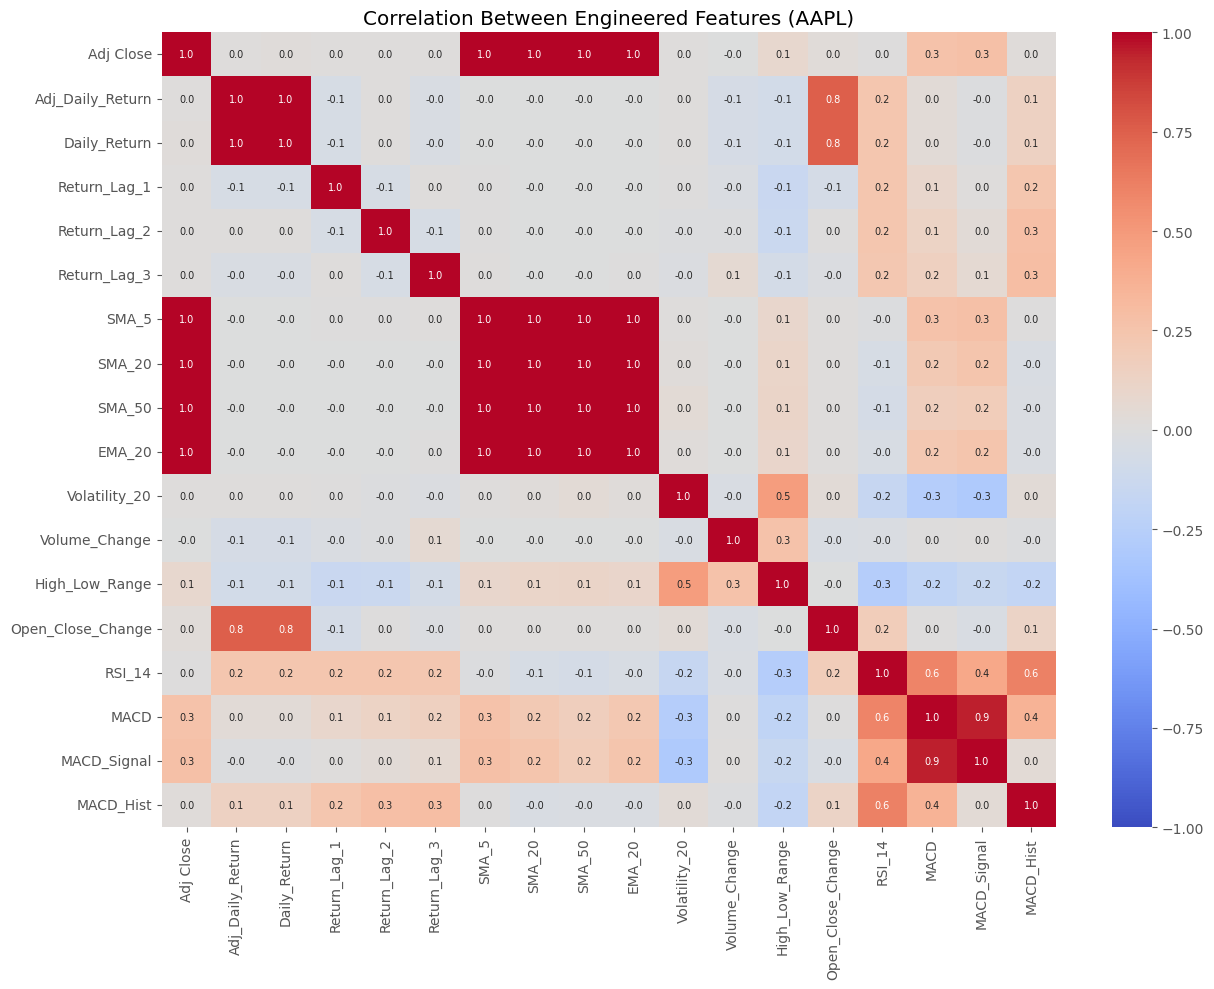

In [21]:
ml = pd.read_csv("../data/ml_ready/AAPL_1D_ml.csv", parse_dates=["Date"])

feature_corr = ml[FEATURES].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(feature_corr, annot=True, fmt=".1f", annot_kws={"size": 7}, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Engineered Features (AAPL)")
plt.tight_layout()
save_fig("feature_correlation")
plt.show()

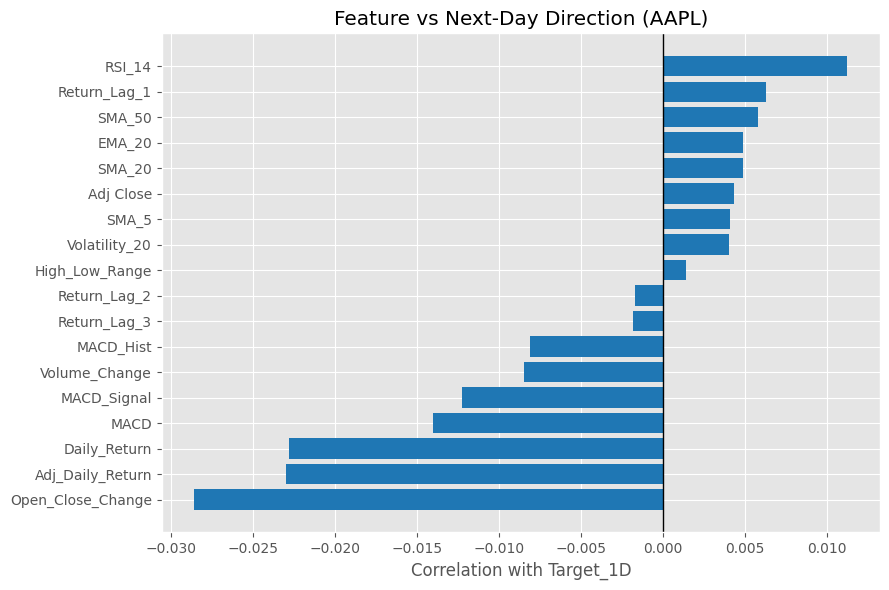

Largest absolute correlation with the target: 0.029


In [22]:
target_corr = ml[FEATURES + ["Target_1D"]].corr()["Target_1D"].drop("Target_1D").sort_values()

plt.figure(figsize=(9, 6))
plt.barh(target_corr.index, target_corr.values, color="#1f77b4")
plt.axvline(0, color="black", lw=1)
plt.xlabel("Correlation with Target_1D")
plt.title("Feature vs Next-Day Direction (AAPL)")
plt.tight_layout()
save_fig("feature_target_correlation")
plt.show()

print(f"Largest absolute correlation with the target: {target_corr.abs().max():.3f}")

### Observation

- Several features are **almost identical**: `Adj Close`, `SMA_5`, `SMA_20`, `SMA_50` and `EMA_20` have correlations above 0.99 (they all follow the price level), `Daily_Return` equals `Adj_Daily_Return` (0.9998), and `MACD` and `MACD_Signal` are also strongly related (0.95). This is **multicollinearity**: these features carry the same information. Tree-based models tolerate it, but Logistic Regression is more sensitive to it. Replacing price-level features with ratios (such as Close / SMA_20) is a possible improvement.
- **No feature has a meaningful linear relationship with the next-day direction** (the largest absolute correlation is below 0.03). This matches Section 7: the next-day direction is very hard to predict, so **modest 1-day accuracy is expected** and does not mean the models are broken.

## Summary of Key Findings

| # | Finding | Evidence | Why it matters |
|---|---------|----------|----------------|
| 1 | Data is clean, except 6 zero-volume days on Indian stocks | 0 missing values; zero volume on the same 6 dates for all 4 Indian stocks | Zero volume gives infinite `Volume_Change`; these rows must be removed before modelling |
| 2 | Returns are not normal; tails are fat | Jarque-Bera p ≈ 0; excess kurtosis 3.7 to 9.6; extreme days 4 to 6 times more common | Normality-based risk assumptions are wrong |
| 3 | US stocks: higher return and higher risk | Welch t-test p = 0.02; Levene p ≈ 0 | Return and risk differ between markets |
| 4 | US and Indian stocks are weakly correlated | Average correlation 0.09 across markets vs 0.55 (US) and 0.34 (India) within markets | Diversification benefit |
| 5 | Prices are non-stationary, returns are stationary | ADF test | Use returns/ratios, not raw prices |
| 6 | Volatility clusters, direction is not predictable | ACF of squared returns vs returns | Direction prediction is inherently hard |
| 7 | No reliable weekday effect | Kruskal-Wallis; none significant after Bonferroni | Weekday is not a useful feature |
| 8 | "Up" class dominates at long horizons; features are redundant and weak | 20D "Up" up to 66%; SMA/EMA/Adj Close correlation above 0.99; feature-target correlation below 0.03 | Compare models with the baseline; consider reducing redundant features |

## Conclusion

This notebook extended the price-based EDA with a statistical study of daily returns for all 8 stocks. Returns are **fat-tailed and non-normal**, **stationary**, and show **volatility clustering** but almost no predictable direction. US stocks delivered higher returns with higher risk than Indian stocks, and the two markets are only weakly correlated. These findings explain the nature of the prediction problem handled in the machine-learning notebooks (07 to 10): next-day direction is very close to random, class balance changes with the horizon, and many engineered features are redundant.

> **Note:** This is a historical, educational analysis. Past behaviour does not guarantee future results and nothing here is financial advice.